In [1]:
import numpy as np

def d_log_return_d_sigma(sigma, dt, Z):
    """
    Derivative of log return with respect to volatility (sigma)
    
    Parameters:
    sigma : float
        Volatility
    dt : float
        Time step (e.g., 1/252)
    Z : float or np.array
        Standard normal random variable(s)
        
    Returns:
    derivative : float or np.array
    """
    return -sigma * dt + np.sqrt(dt) * Z


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_24440\126303251.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2023-01-01", end="2024-01-01", progress=False)


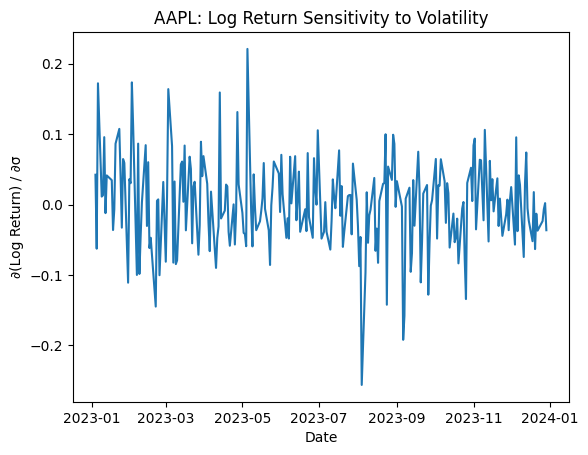

In [3]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# Download data
ticker = "AAPL"
data = yf.download(ticker, start="2023-01-01", end="2024-01-01", progress=False)

# Log returns
prices = data["Close"]
log_returns = np.log(prices / prices.shift(1)).dropna()

# Parameters
dt = 1 / 252
sigma = (log_returns.std() * np.sqrt(252)).item()   # force scalar
mu = (log_returns.mean() * 252).item()              # force scalar

# Back out realized Z_t
Z = (log_returns - (mu - 0.5 * sigma**2) * dt) / (sigma * np.sqrt(dt))

# Derivative of log return w.r.t volatility
d_log_return_d_sigma = -sigma * dt + np.sqrt(dt) * Z

# Plot
plt.figure()
plt.plot(d_log_return_d_sigma.index, d_log_return_d_sigma.values)
plt.xlabel("Date")
plt.ylabel("∂(Log Return) / ∂σ")
plt.title(f"{ticker}: Log Return Sensitivity to Volatility")
plt.show()


[*********************100%***********************]  1 of 1 completed


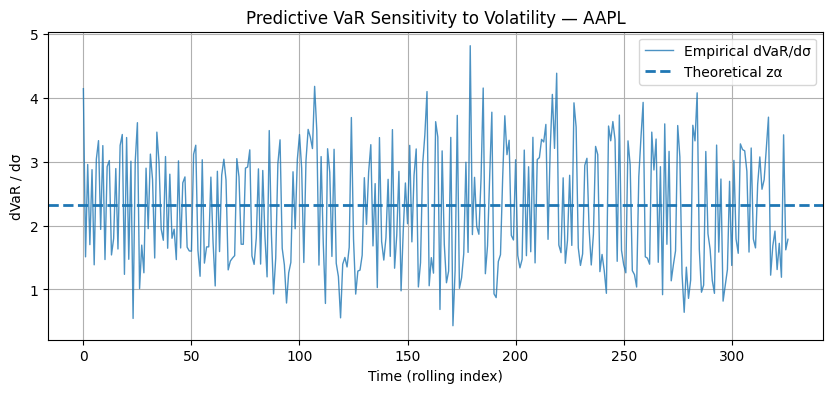

[*********************100%***********************]  1 of 1 completed


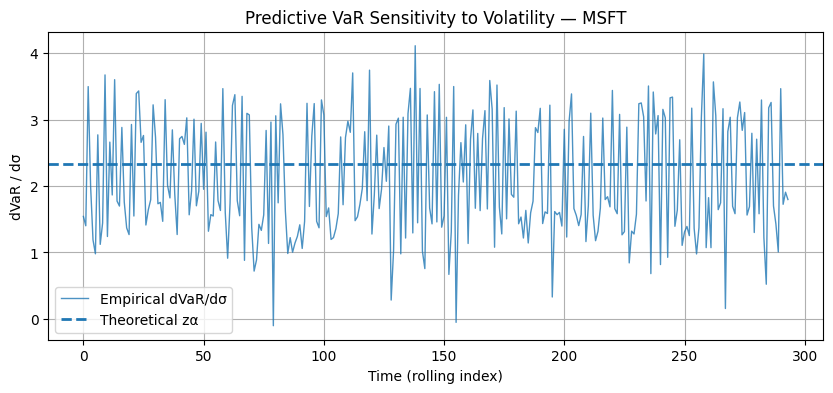

[*********************100%***********************]  1 of 1 completed


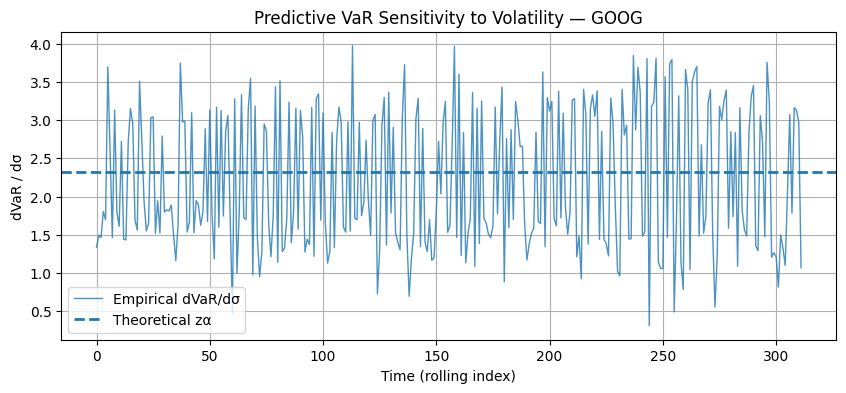

[*********************100%***********************]  1 of 1 completed


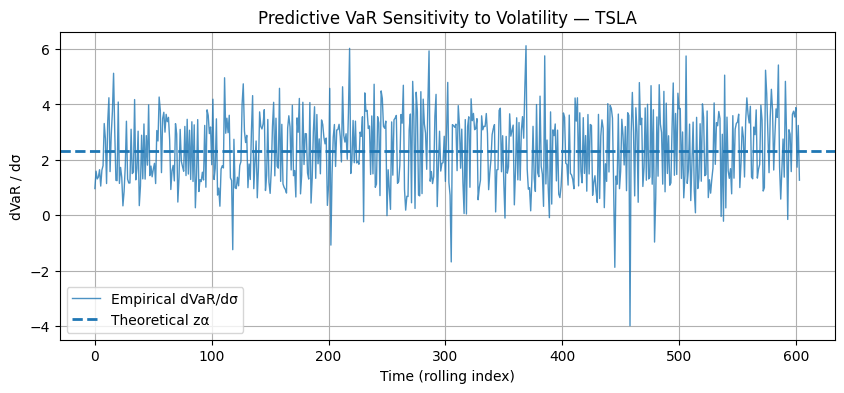

In [10]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL", "MSFT", "GOOG", "TSLA"]
start = "2015-01-01"
end = "2025-01-01"
window = 250
alpha = 0.99
z = norm.ppf(alpha)

min_dsigma = 1e-4   # filter tiny volatility changes

# -----------------------------
# Loop over assets
# -----------------------------
for ticker in tickers:
    df = yf.download(ticker, start=start, end=end, auto_adjust=True)
    prices = df["Close"].dropna()

    returns = np.log(prices / prices.shift(1)).dropna().values

    VaR = []
    sigma = []

    for i in range(window, len(returns)):
        r_win = returns[i - window:i]
        mu_t = r_win.mean()
        sigma_t = r_win.std(ddof=1)
        VaR_t = mu_t + z * sigma_t

        VaR.append(VaR_t)
        sigma.append(sigma_t)

    VaR = np.array(VaR)
    sigma = np.array(sigma)

    # Discrete differentiation
    dVaR = np.diff(VaR)
    dSigma = np.diff(sigma)

    # Filter unstable points
    mask = np.abs(dSigma) > min_dsigma
    sensitivity = dVaR[mask] / dSigma[mask]

    # Time axis
    t = np.arange(len(sensitivity))

    # -----------------------------
    # Plot
    # -----------------------------
    plt.figure(figsize=(10, 4))
    plt.plot(t, sensitivity, linewidth=1, alpha=0.8, label="Empirical dVaR/dσ")
    plt.axhline(z, linestyle="--", linewidth=2, label="Theoretical zα")

    plt.title(f"Predictive VaR Sensitivity to Volatility — {ticker}")
    plt.xlabel("Time (rolling index)")
    plt.ylabel("dVaR / dσ")
    plt.legend()
    plt.grid(True)
    plt.show()


Processing AAPL...


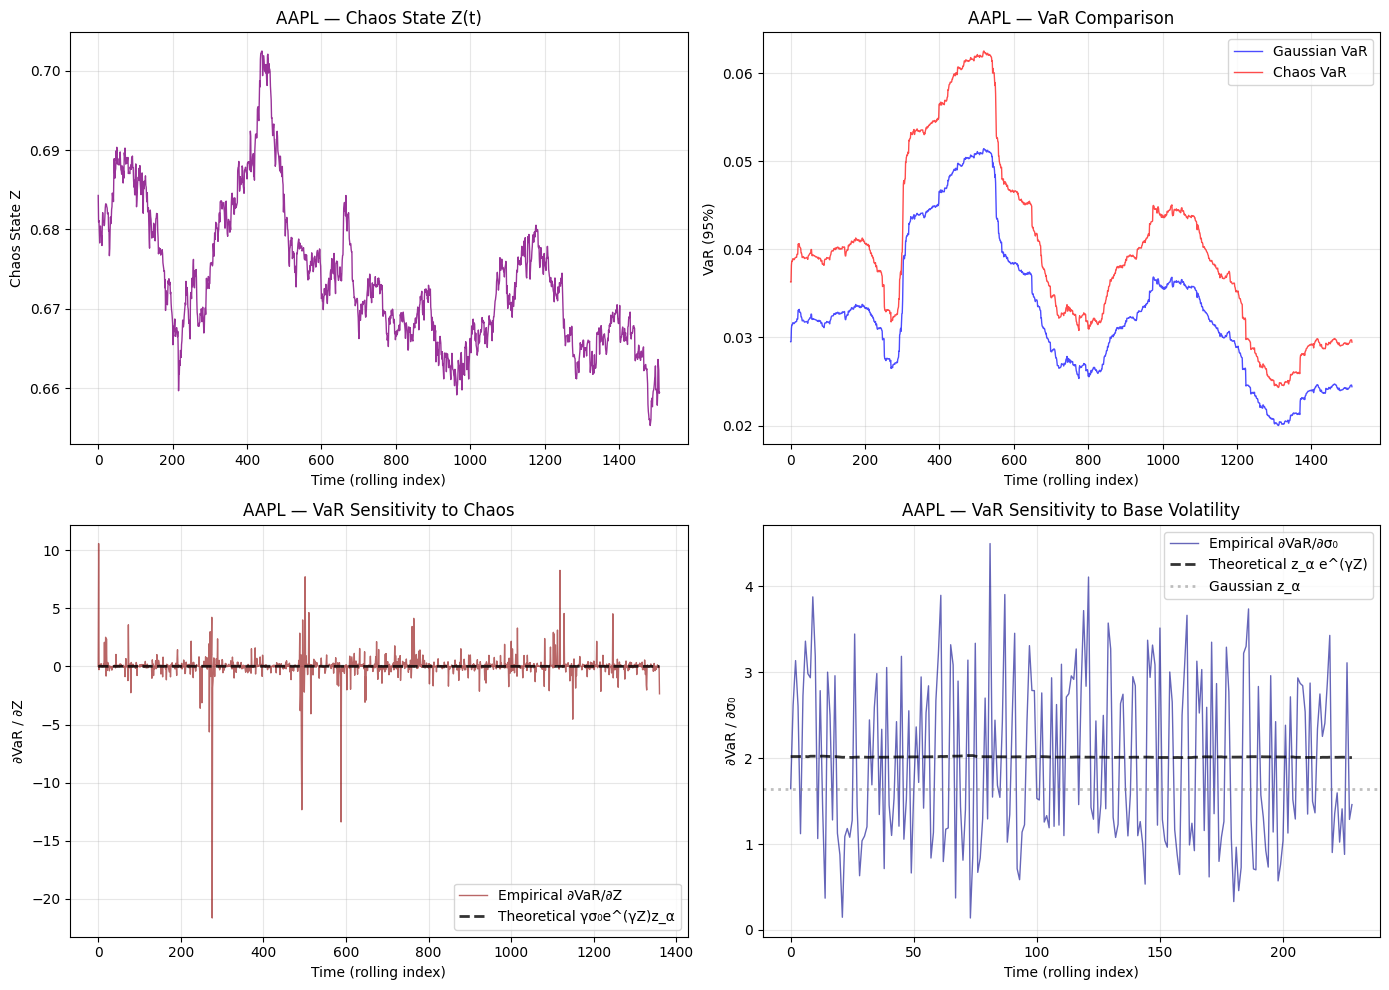


AAPL Summary:
  Mean Chaos State: 0.6739
  Mean VaR Inflation: 21.76%
  Mean ∂VaR/∂Z (empirical): 0.004429
  Mean ∂VaR/∂Z (theoretical): 0.011734
  Mean ∂VaR/∂σ₀ (empirical): 1.9534
  Mean ∂VaR/∂σ₀ (theoretical): 2.0131
  Gaussian baseline (z_α): 1.6449
Processing MSFT...


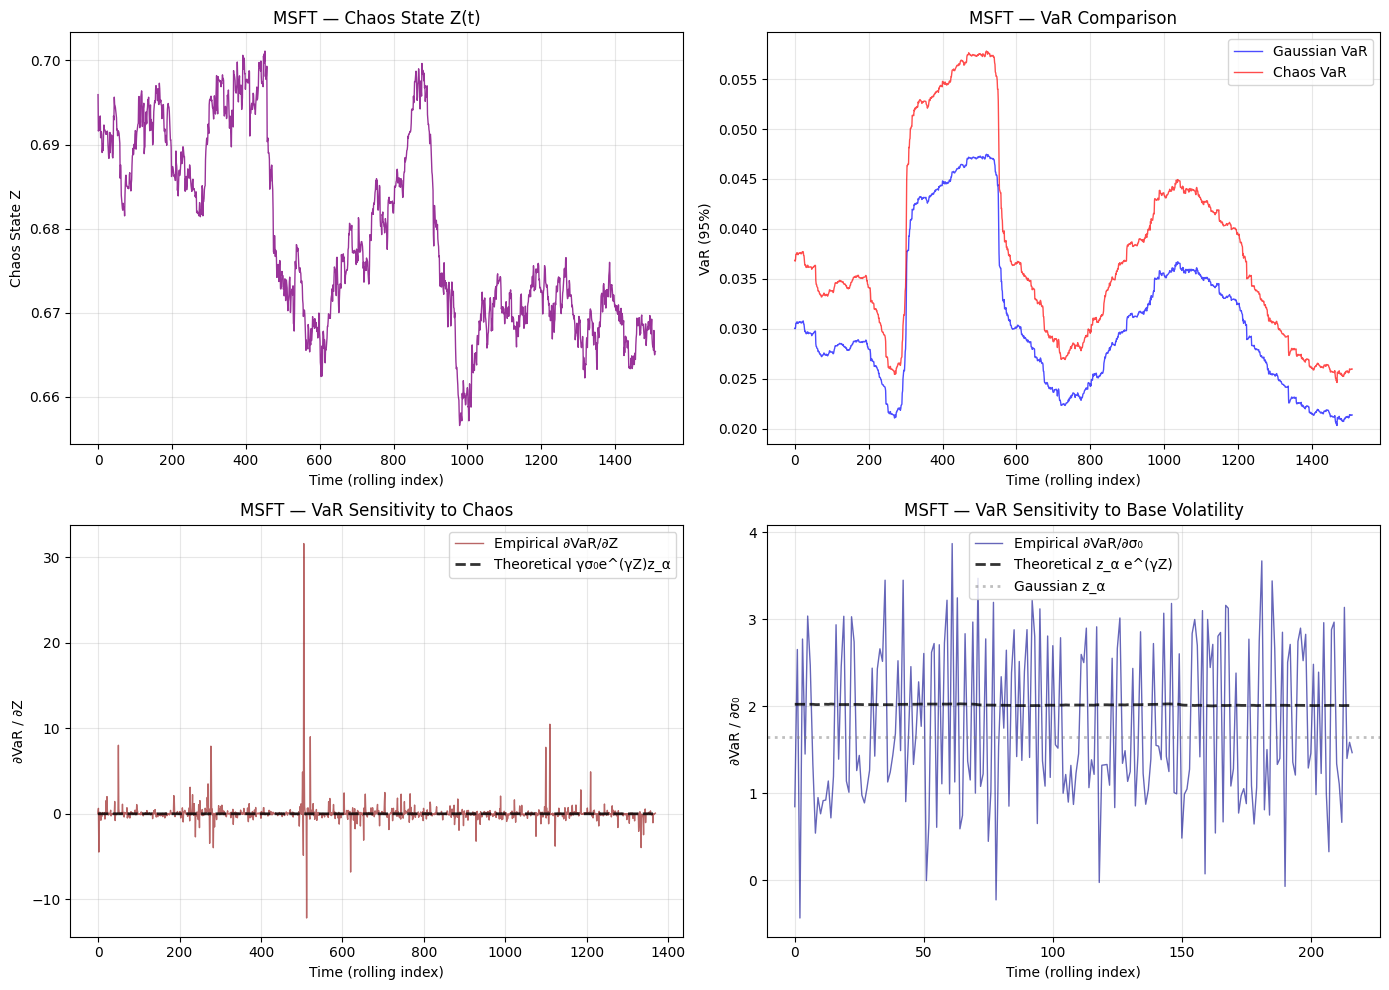


MSFT Summary:
  Mean Chaos State: 0.6791
  Mean VaR Inflation: 21.89%
  Mean ∂VaR/∂Z (empirical): 0.071096
  Mean ∂VaR/∂Z (theoretical): 0.010982
  Mean ∂VaR/∂σ₀ (empirical): 1.7820
  Mean ∂VaR/∂σ₀ (theoretical): 2.0172
  Gaussian baseline (z_α): 1.6449
Processing TSLA...


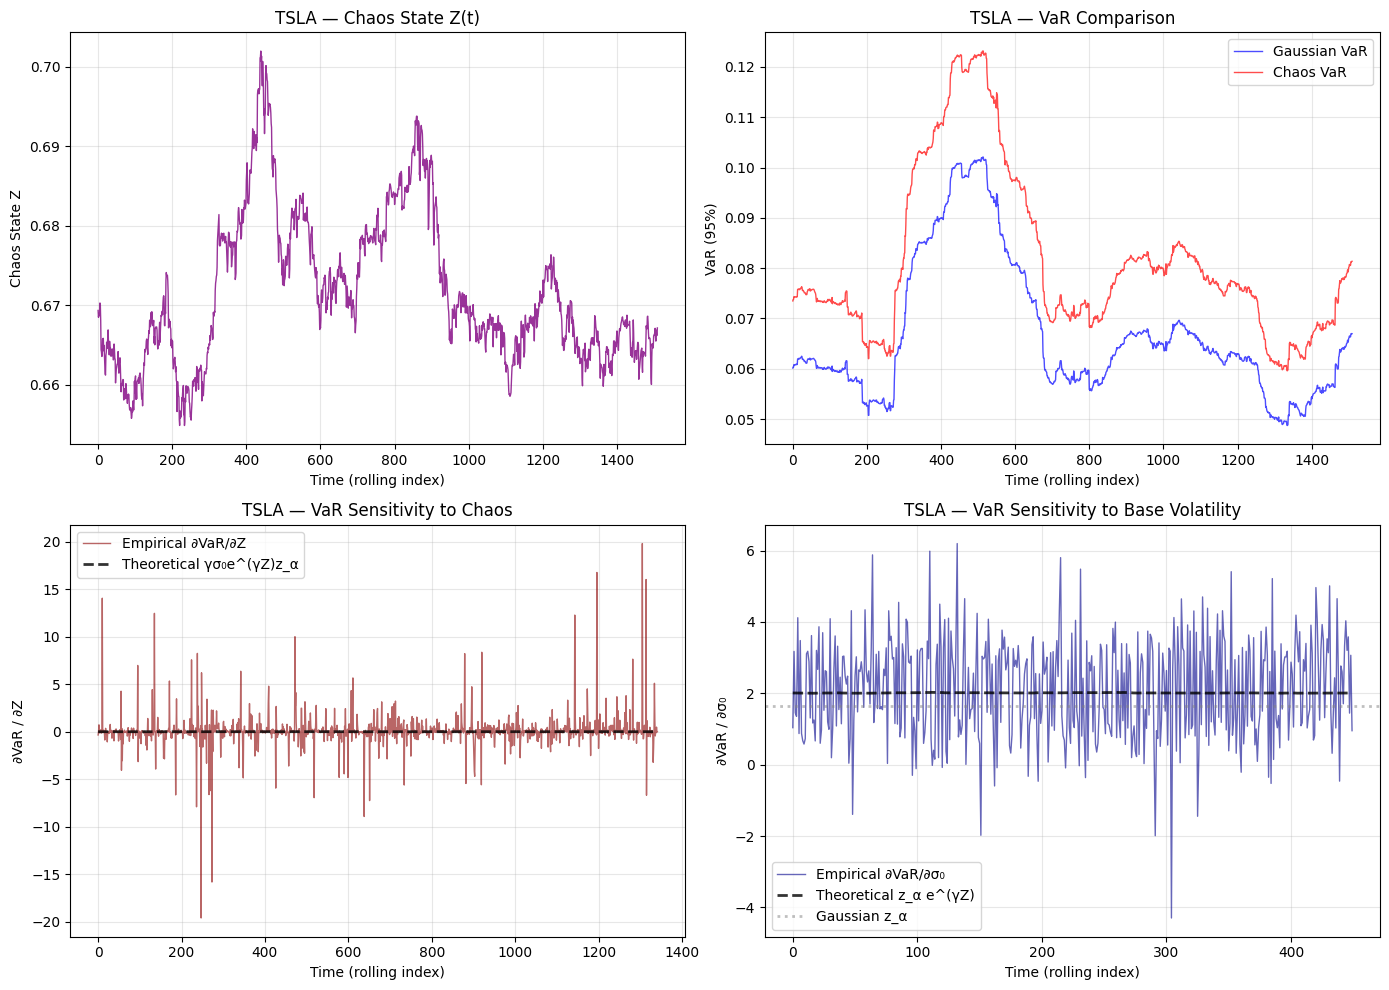


TSLA Summary:
  Mean Chaos State: 0.6717
  Mean VaR Inflation: 21.84%
  Mean ∂VaR/∂Z (empirical): 0.116694
  Mean ∂VaR/∂Z (theoretical): 0.024021
  Mean ∂VaR/∂σ₀ (empirical): 2.1237
  Mean ∂VaR/∂σ₀ (theoretical): 2.0125
  Gaussian baseline (z_α): 1.6449
Processing BTC-USD...


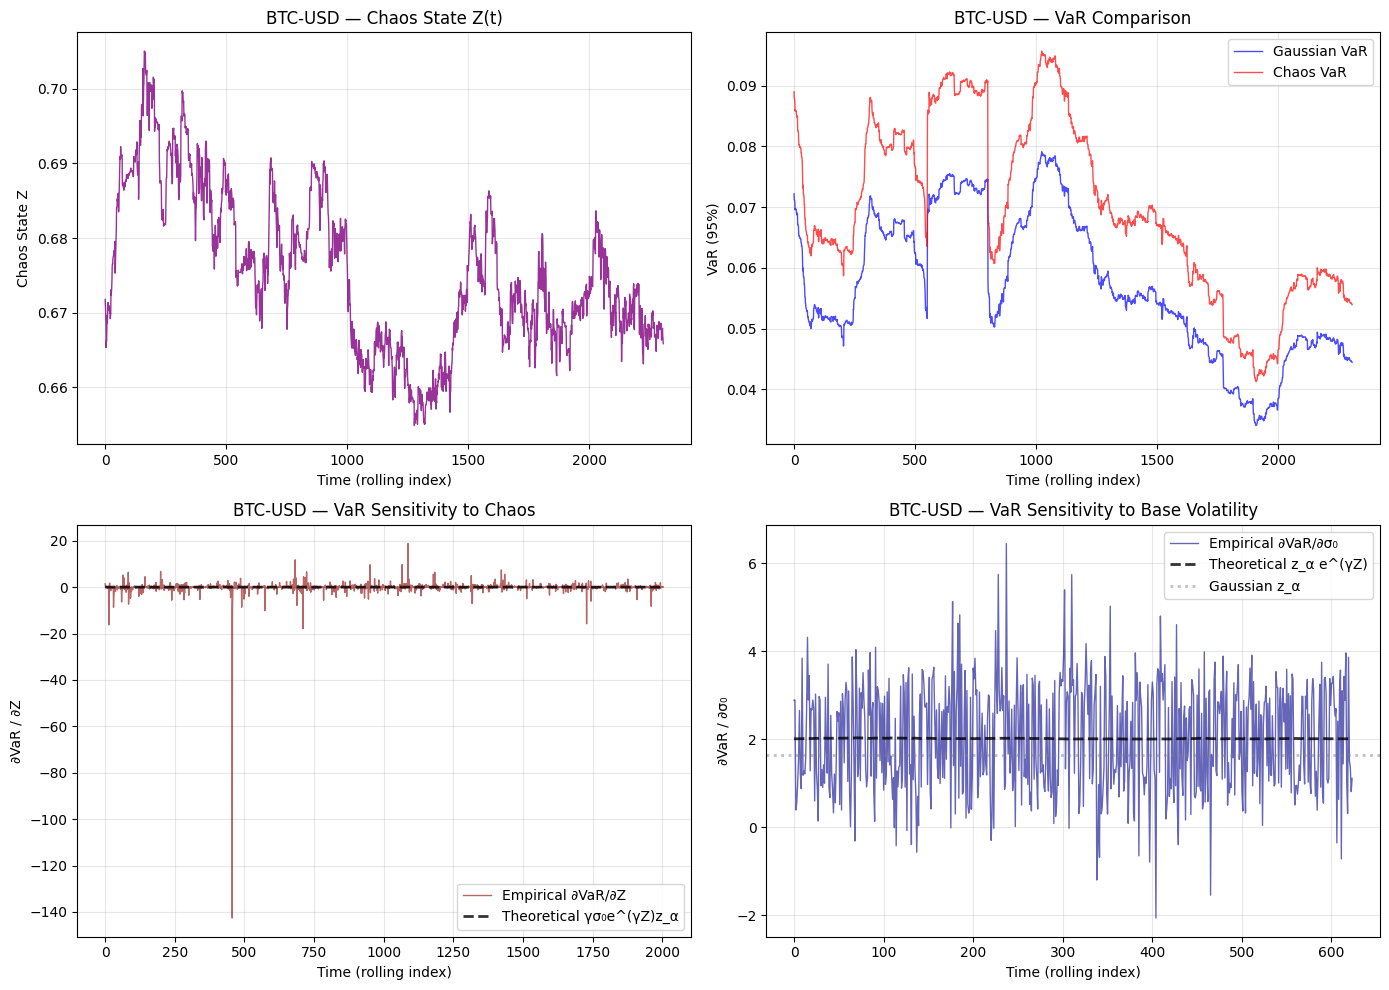


BTC-USD Summary:
  Mean Chaos State: 0.6755
  Mean VaR Inflation: 22.11%
  Mean ∂VaR/∂Z (empirical): -0.095742
  Mean ∂VaR/∂Z (theoretical): 0.020706
  Mean ∂VaR/∂σ₀ (empirical): 2.0244
  Mean ∂VaR/∂σ₀ (theoretical): 2.0145
  Gaussian baseline (z_α): 1.6449

Analysis complete!


In [16]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.spatial.distance import pdist, squareform

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL", "MSFT", "TSLA", "BTC-USD"]
start = "2018-01-01"
end = "2025-01-01"
window = 250
alpha = 0.95
z = norm.ppf(alpha)
gamma = 0.3  # Chaos sensitivity parameter

min_dZ = 1e-4  # Filter tiny chaos changes

# -----------------------------
# Chaos State Computation
# -----------------------------
def compute_chaos_state(returns, m=3, tau=1, threshold_pct=10):
    """Simplified chaos state from recurrence analysis"""
    # Ensure returns is 1D array - force it aggressively
    if hasattr(returns, 'values'):
        returns = returns.values
    returns = np.asarray(returns).squeeze()
    
    # Time-delay embedding
    N = len(returns)
    M = N - (m - 1) * tau
    if M <= 0:
        return 0.1  # Default low chaos for insufficient data
    
    embedded = np.zeros((M, m))
    for i in range(m):
        start_idx = i * tau
        end_idx = start_idx + M
        slice_data = returns[start_idx:end_idx]
        # Force to 1D
        embedded[:, i] = np.asarray(slice_data).squeeze()
    
    # Recurrence plot
    dist_matrix = squareform(pdist(embedded, metric='euclidean'))
    threshold = np.percentile(dist_matrix, threshold_pct)
    R = (dist_matrix <= threshold).astype(int)
    
    # RQA metrics
    RR = np.sum(R) / (M * M)
    
    # Determinism
    diag_lines = []
    for k in range(1, M):
        diag = np.diag(R, k)
        in_line = False
        length = 0
        for val in diag:
            if val == 1:
                length += 1
                in_line = True
            else:
                if length >= 2:
                    diag_lines.append(length)
                length = 0
        if length >= 2:
            diag_lines.append(length)
    
    DET = sum(diag_lines) / np.sum(R) if len(diag_lines) > 0 else 0
    
    # Simple entropy
    if len(diag_lines) > 0:
        hist, _ = np.histogram(diag_lines, bins=range(2, max(diag_lines)+2))
        probs = hist / sum(hist)
        probs = probs[probs > 0]
        ENTR = -np.sum(probs * np.log(probs))
    else:
        ENTR = 0
    
    # Chaos state
    Z = (1 - DET) + ENTR + RR
    Z_norm = Z / (1 + abs(Z))
    
    return Z_norm

# -----------------------------
# Loop over assets
# -----------------------------
for ticker in tickers:
    print(f"Processing {ticker}...")
    df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    prices = df["Close"].dropna()
    returns = np.log(prices / prices.shift(1)).dropna().values
    
    VaR_gauss = []
    VaR_chaos = []
    sigma_base = []
    Z_series = []
    
    for i in range(window, len(returns)):
        r_win = returns[i - window:i]
        # Force to 1D numpy array
        r_win = np.asarray(r_win).ravel()
        mu_t = r_win.mean()
        sigma_t = r_win.std(ddof=1)
        
        # Chaos state for this window
        Z_t = compute_chaos_state(r_win)
        
        # Gaussian VaR
        VaR_g = mu_t + z * sigma_t
        
        # Chaos-conditioned VaR: σ(Z) = σ₀ * exp(γZ)
        sigma_chaos = sigma_t * np.exp(gamma * Z_t)
        VaR_c = mu_t + z * sigma_chaos
        
        VaR_gauss.append(VaR_g)
        VaR_chaos.append(VaR_c)
        sigma_base.append(sigma_t)
        Z_series.append(Z_t)
    
    VaR_gauss = np.array(VaR_gauss)
    VaR_chaos = np.array(VaR_chaos)
    sigma_base = np.array(sigma_base)
    Z_series = np.array(Z_series)
    
    # -----------------------------
    # Empirical Derivatives
    # -----------------------------
    
    # 1. dVaR_chaos/dZ - How VaR responds to chaos changes
    dVaR_chaos = np.diff(VaR_chaos)
    dZ = np.diff(Z_series)
    
    mask_Z = np.abs(dZ) > min_dZ
    sensitivity_Z = dVaR_chaos[mask_Z] / dZ[mask_Z]
    
    # Theoretical: ∂VaR/∂Z = γ σ₀ e^(γZ) z_α
    theoretical_dVaR_dZ = gamma * sigma_base[:-1][mask_Z] * np.exp(gamma * Z_series[:-1][mask_Z]) * z
    
    # 2. dVaR_chaos/dσ₀ - How chaos VaR responds to base volatility
    dVaR = np.diff(VaR_chaos)
    dSigma = np.diff(sigma_base)
    
    mask_sigma = np.abs(dSigma) > min_dZ
    sensitivity_sigma = dVaR[mask_sigma] / dSigma[mask_sigma]
    
    # Theoretical: ∂VaR/∂σ₀ = z_α e^(γZ)
    theoretical_dVaR_dsigma = z * np.exp(gamma * Z_series[:-1][mask_sigma])
    
    # -----------------------------
    # Plotting
    # -----------------------------
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Plot 1: Chaos State Evolution
    ax1 = axes[0, 0]
    ax1.plot(Z_series, linewidth=1, alpha=0.8, color='purple')
    ax1.set_title(f"{ticker} — Chaos State Z(t)")
    ax1.set_xlabel("Time (rolling index)")
    ax1.set_ylabel("Chaos State Z")
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: VaR Comparison
    ax2 = axes[0, 1]
    ax2.plot(VaR_gauss, linewidth=1, alpha=0.7, label='Gaussian VaR', color='blue')
    ax2.plot(VaR_chaos, linewidth=1, alpha=0.7, label='Chaos VaR', color='red')
    ax2.set_title(f"{ticker} — VaR Comparison")
    ax2.set_xlabel("Time (rolling index)")
    ax2.set_ylabel("VaR (95%)")
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: ∂VaR/∂Z Sensitivity
    ax3 = axes[1, 0]
    t_Z = np.arange(len(sensitivity_Z))
    ax3.plot(t_Z, sensitivity_Z, linewidth=1, alpha=0.6, label='Empirical ∂VaR/∂Z', color='darkred')
    ax3.plot(t_Z, theoretical_dVaR_dZ, linewidth=2, linestyle='--', alpha=0.8, 
             label='Theoretical γσ₀e^(γZ)z_α', color='black')
    ax3.set_title(f"{ticker} — VaR Sensitivity to Chaos")
    ax3.set_xlabel("Time (rolling index)")
    ax3.set_ylabel("∂VaR / ∂Z")
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # Plot 4: ∂VaR/∂σ₀ Sensitivity
    ax4 = axes[1, 1]
    t_sigma = np.arange(len(sensitivity_sigma))
    ax4.plot(t_sigma, sensitivity_sigma, linewidth=1, alpha=0.6, label='Empirical ∂VaR/∂σ₀', color='darkblue')
    ax4.plot(t_sigma, theoretical_dVaR_dsigma, linewidth=2, linestyle='--', alpha=0.8,
             label='Theoretical z_α e^(γZ)', color='black')
    ax4.axhline(z, linestyle=':', linewidth=2, alpha=0.5, label='Gaussian z_α', color='gray')
    ax4.set_title(f"{ticker} — VaR Sensitivity to Base Volatility")
    ax4.set_xlabel("Time (rolling index)")
    ax4.set_ylabel("∂VaR / ∂σ₀")
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'chaos_sensitivity_{ticker}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # -----------------------------
    # Summary Statistics
    # -----------------------------
    print(f"\n{ticker} Summary:")
    print(f"  Mean Chaos State: {Z_series.mean():.4f}")
    print(f"  Mean VaR Inflation: {((VaR_chaos.mean() / VaR_gauss.mean()) - 1)*100:.2f}%")
    print(f"  Mean ∂VaR/∂Z (empirical): {np.mean(sensitivity_Z):.6f}")
    print(f"  Mean ∂VaR/∂Z (theoretical): {np.mean(theoretical_dVaR_dZ):.6f}")
    print(f"  Mean ∂VaR/∂σ₀ (empirical): {np.mean(sensitivity_sigma):.4f}")
    print(f"  Mean ∂VaR/∂σ₀ (theoretical): {np.mean(theoretical_dVaR_dsigma):.4f}")
    print(f"  Gaussian baseline (z_α): {z:.4f}")

print("\nAnalysis complete!")

# Chaos-Conditioned Risk Framework: Mathematical Formulation

## 1. Core Model Structure

### Return Generation Process
Returns are primitive, chaos modulates the probability distribution:

$$r_t = \mu + \sigma(Z_t) \varepsilon_t$$

where $\varepsilon_t \sim N(0,1)$ and $\sigma(Z_t)$ is chaos-conditioned volatility.

### Chaos-Modulated Volatility
$$\sigma(Z_t) = \sigma_0 \cdot e^{\gamma Z_t}$$

where:
- $\sigma_0$ = base volatility
- $\gamma$ = chaos sensitivity parameter (default: 0.3)
- $Z_t$ = chaos state index

---

## 2. Chaos State Index

The latent chaos state is computed from dynamical systems metrics:

$$Z_t = 2.0 \cdot \max(\lambda, 0) + (1 - \text{DET}) + \text{ENTR} + \text{RR}$$

Normalized version:
$$Z_{\text{norm}} = \frac{Z}{1 + |Z|}$$

where:
- $\lambda$ = Lyapunov exponent (trajectory divergence)
- $\text{DET}$ = Determinism from RQA (predictability)
- $\text{ENTR}$ = Entropy from diagonal line distribution
- $\text{RR}$ = Recurrence rate

---

## 3. Risk Measures

### Gaussian VaR (Baseline)
$$\text{VaR}_{\alpha}^{\text{Gauss}} = \mu + \sigma_0 \cdot z_{\alpha}$$

### Chaos-Conditioned VaR
$$\text{VaR}_{\alpha}^{\text{Chaos}} = \mu + \sigma_0 \cdot e^{\gamma Z_t} \cdot z_{\alpha}$$

### Expected Shortfall (CVaR)
$$\text{ES}_{\alpha}^{\text{Chaos}} = \mu + \sigma_0 \cdot e^{\gamma Z_t} \cdot \frac{\phi(z_{\alpha})}{1 - \alpha}$$

where $\phi(\cdot)$ is the standard normal PDF.

---

## 4. Extreme Value Theory (EVT)

### Standard EVT VaR
$$\text{VaR}_{\alpha}^{\text{EVT}} = u + \frac{\beta}{\xi} \left[ \left( \frac{(1-\alpha) N}{N_u} \right)^{-\xi} - 1 \right]$$

where:
- $u$ = threshold (typically 90-95th percentile)
- $\beta$ = GPD scale parameter
- $\xi$ = GPD shape parameter (tail index)
- $N_u$ = number of exceedances above $u$

### Chaos-Conditioned EVT Scale
The scale parameter inflates exponentially with chaos:

$$\beta(Z_t) = \beta_0 \cdot e^{\gamma Z_t}$$

### Regime-Conditional EVT VaR
Fit EVT only on high-chaos regime data:

$$\text{VaR}_{\alpha}^{\text{Regime}} = u + \frac{\beta(Z_t)}{\xi} \left[ \left( \frac{(1-\alpha) N}{N_u} \right)^{-\xi} - 1 \right]$$

where data is filtered: $\{r_t : Z_t > Q_{0.75}(Z)\}$

---

## 5. Differentiation Analysis

### Return-Level Derivatives

**Sensitivity to base volatility:**
$$\frac{\partial r_t}{\partial \sigma_0} = \varepsilon_t \cdot e^{\gamma Z_t}$$

**Sensitivity to chaos state:**
$$\frac{\partial r_t}{\partial Z} = \gamma \sigma_0 \cdot e^{\gamma Z_t} \cdot \varepsilon_t$$

### Volatility Derivatives

**Chaos-volatility relationship:**
$$\frac{\partial \sigma}{\partial Z} = \gamma \sigma_0 \cdot e^{\gamma Z_t}$$

**Elasticity (percentage sensitivity):**
$$\mathcal{E}_{\sigma,Z} = \frac{\partial \sigma}{\partial Z} \cdot \frac{Z}{\sigma} = \gamma Z$$

### VaR Derivatives

**VaR sensitivity to chaos:**
$$\frac{\partial \text{VaR}}{\partial Z} = \gamma \sigma_0 \cdot e^{\gamma Z_t} \cdot z_{\alpha}$$

**VaR sensitivity to base volatility:**
$$\frac{\partial \text{VaR}}{\partial \sigma_0} = e^{\gamma Z_t} \cdot z_{\alpha}$$

### EVT Derivatives

**Scale parameter sensitivity:**
$$\frac{\partial \beta}{\partial Z} = \gamma \beta_0 \cdot e^{\gamma Z_t}$$

**EVT VaR sensitivity:**
$$\frac{\partial \text{VaR}^{\text{EVT}}}{\partial Z} = \frac{\gamma \beta(Z_t)}{\xi} \left[ \left( \frac{(1-\alpha) N}{N_u} \right)^{-\xi} - 1 \right]$$

### Cross-Derivative (Chaos-Tail Interaction)

$$\frac{\partial^2 \text{VaR}^{\text{EVT}}}{\partial Z \partial \xi} = -\frac{\gamma \beta(Z_t)}{\xi^2} \left[ \left( \frac{(1-\alpha) N}{N_u} \right)^{-\xi} - 1 \right]$$

This captures how tail heaviness amplifies chaos effects.

---

## 6. Recurrence Quantification Analysis (RQA)

### Recurrence Plot
Binary matrix indicating phase space recurrences:
$$R_{i,j} = \Theta(\epsilon - \|\mathbf{x}_i - \mathbf{x}_j\|)$$

where $\Theta$ is the Heaviside function and $\epsilon$ is the recurrence threshold.

### Time-Delay Embedding
$$\mathbf{x}_i = [r_i, r_{i+\tau}, r_{i+2\tau}, \ldots, r_{i+(m-1)\tau}]$$

where:
- $m$ = embedding dimension (default: 3)
- $\tau$ = time delay (default: 1)

### RQA Metrics

**Recurrence Rate:**
$$\text{RR} = \frac{1}{N^2} \sum_{i,j=1}^{N} R_{i,j}$$

**Determinism:**
$$\text{DET} = \frac{\sum_{l=l_{\min}}^{N} l \cdot P(l)}{\sum_{l=1}^{N} l \cdot P(l)}$$

where $P(l)$ is the distribution of diagonal line lengths.

**Laminarity:**
$$\text{LAM} = \frac{\sum_{v=v_{\min}}^{N} v \cdot P(v)}{\sum_{v=1}^{N} v \cdot P(v)}$$

where $P(v)$ is the distribution of vertical line lengths.

**Entropy:**
$$\text{ENTR} = -\sum_{l=l_{\min}}^{N} p(l) \ln p(l)$$

where $p(l) = P(l) / \sum P(l)$ is the probability distribution.

---

## 7. Additional Risk Metrics

### Escape Probability
Measures regime transition likelihood:
$$p_{\text{escape}}(t) = 1 - \frac{1}{N} \sum_{j=1}^{N} R_{t,j}$$

Average:
$$\bar{p}_{\text{escape}} = \frac{1}{N} \sum_{t=1}^{N} p_{\text{escape}}(t)$$

### Entropic Risk Measure
Distribution-free risk using KDE:
$$\rho_t = -\log p(\mathbf{x}_t)$$

where $p(\mathbf{x}_t)$ is estimated via kernel density estimation on embedded space.

### Transition-Aware VaR
$$\text{VaR}_{\text{transition}} = \text{VaR}_{\text{chaos}} \cdot (1 + p_{\text{escape}})$$

### Entropic VaR
$$\text{VaR}_{\text{entropic}} = \text{VaR}_{\text{chaos}} \cdot (1 + \rho)$$

---

## 8. Dynamical Systems Metrics

### Hurst Exponent (Long-Range Dependence)
$$H = \frac{\log(R/S)}{\log(n)}$$

Interpretation:
- $H < 0.5$: Mean-reverting
- $H \approx 0.5$: Random walk (Brownian motion)
- $H > 0.5$: Persistent/trending

### Lyapunov Exponent (Chaos Indicator)
Maximum rate of nearby trajectory divergence:
$$\lambda = \lim_{t \to \infty} \frac{1}{t} \log \frac{\|\delta \mathbf{x}(t)\|}{\|\delta \mathbf{x}(0)\|}$$

Interpretation:
- $\lambda < 0$: Stable (trajectories converge)
- $\lambda \approx 0$: Neutral stability
- $\lambda > 0$: Chaotic (trajectories diverge exponentially)

---

## 9. Model Amplification Factors

### Volatility Amplification
$$A_{\sigma}(Z) = \frac{\sigma(Z)}{\sigma_0} = e^{\gamma Z}$$

### Tail Thickness Multiplier
$$A_{\beta}(Z) = \frac{\beta(Z)}{\beta_0} = e^{\gamma Z}$$

### VaR Inflation Rate
$$\text{Inflation}(\%) = \left( \frac{\text{VaR}_{\text{chaos}}}{\text{VaR}_{\text{Gauss}}} - 1 \right) \times 100$$

---

## 10. Key Theoretical Results

### Probability Shifter Interpretation
Chaos does NOT change the mean:
$$\mathbb{E}[r_t | Z_t] = \mu$$

But it inflates the variance:
$$\text{Var}[r_t | Z_t] = \sigma_0^2 \cdot e^{2\gamma Z_t}$$

### Geometric Amplification Principle
Risk scales **multiplicatively**, not additively:
$$\text{Risk}(Z) = \text{Risk}_0 \cdot e^{\gamma Z} \quad \text{(NOT: } \text{Risk}_0 + \gamma Z \text{)}$$

### Non-Linear Risk Acceleration
The derivative itself depends on current risk:
$$\frac{d\sigma}{dZ} = \gamma \sigma(Z)$$

This creates positive feedback loops in chaotic regimes.

---

## 11. Implementation Parameters

Default values used in the framework:

| Parameter | Symbol | Default Value | Description |
|-----------|--------|---------------|-------------|
| Chaos sensitivity | $\gamma$ | 0.3 | Volatility response to chaos |
| Confidence level | $\alpha$ | 0.95 | VaR/ES confidence |
| Embedding dimension | $m$ | 3 | Phase space dimension |
| Time delay | $\tau$ | 1 | Embedding lag |
| Recurrence threshold | $\epsilon$ | 10th percentile | Distance threshold |
| Min exceedances | $N_{\text{min}}$ | 20 | EVT fitting requirement |
| Chaos regime threshold | $Q_{\text{chaos}}$ | 0.75 | Regime-conditional EVT |

---

## Notation Summary

- $r_t$ : Log-return at time $t$
- $\mu$ : Mean return
- $\sigma_0$ : Base volatility
- $\sigma(Z)$ : Chaos-modulated volatility
- $Z_t$ : Chaos state index
- $\gamma$ : Chaos sensitivity parameter
- $\alpha$ : Confidence level
- $z_\alpha$ : Standard normal quantile at level $\alpha$
- $\lambda$ : Lyapunov exponent
- $H$ : Hurst exponent
- $\xi$ : Tail index (GPD shape parameter)
- $\beta$ : Scale parameter (GPD)
- $\varepsilon_t$ : White noise, $\sim N(0,1)$
- $\phi(\cdot)$ : Standard normal PDF
- $\Phi(\cdot)$ : Standard normal CDF


Processing AAPL...


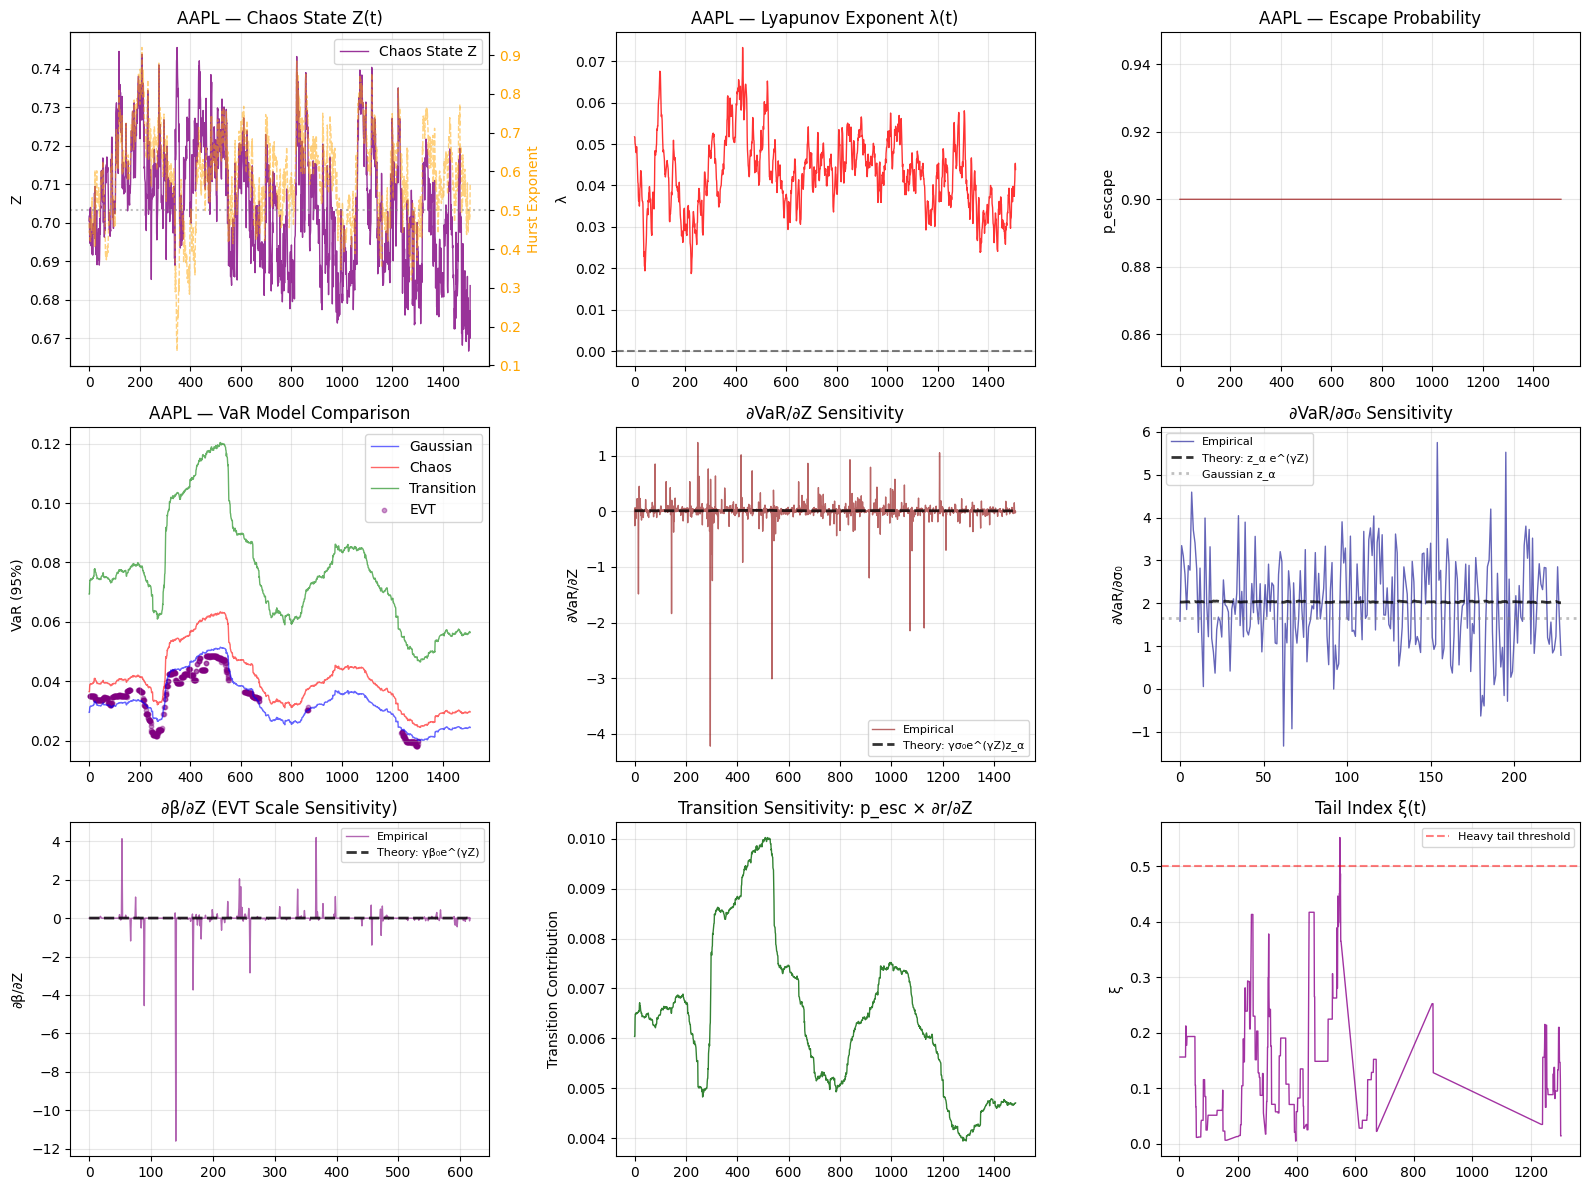


AAPL Enhanced Summary:
  Mean Chaos State Z: 0.7047
  Mean Hurst H: 0.5905 (persistent)
  Mean Lyapunov λ: 0.042734 (chaotic)
  Mean Escape Prob: 0.9000
  VaR Inflation (Chaos/Gauss): 22.87%
  VaR Inflation (Transition/Gauss): 133.45%
  Mean ∂VaR/∂Z (empirical): 0.004709
  Mean ∂VaR/∂Z (theoretical): 0.011800
  Mean ∂VaR/∂σ₀ (empirical): 1.9807
  Mean ∂VaR/∂σ₀ (theoretical): 2.0321
  Mean ∂β/∂Z (empirical): -0.010650
  Mean ∂β/∂Z (theoretical): 0.005684
  Mean Transition Sensitivity: 0.006457
  Gaussian baseline z_α: 1.6449

Processing MSFT...


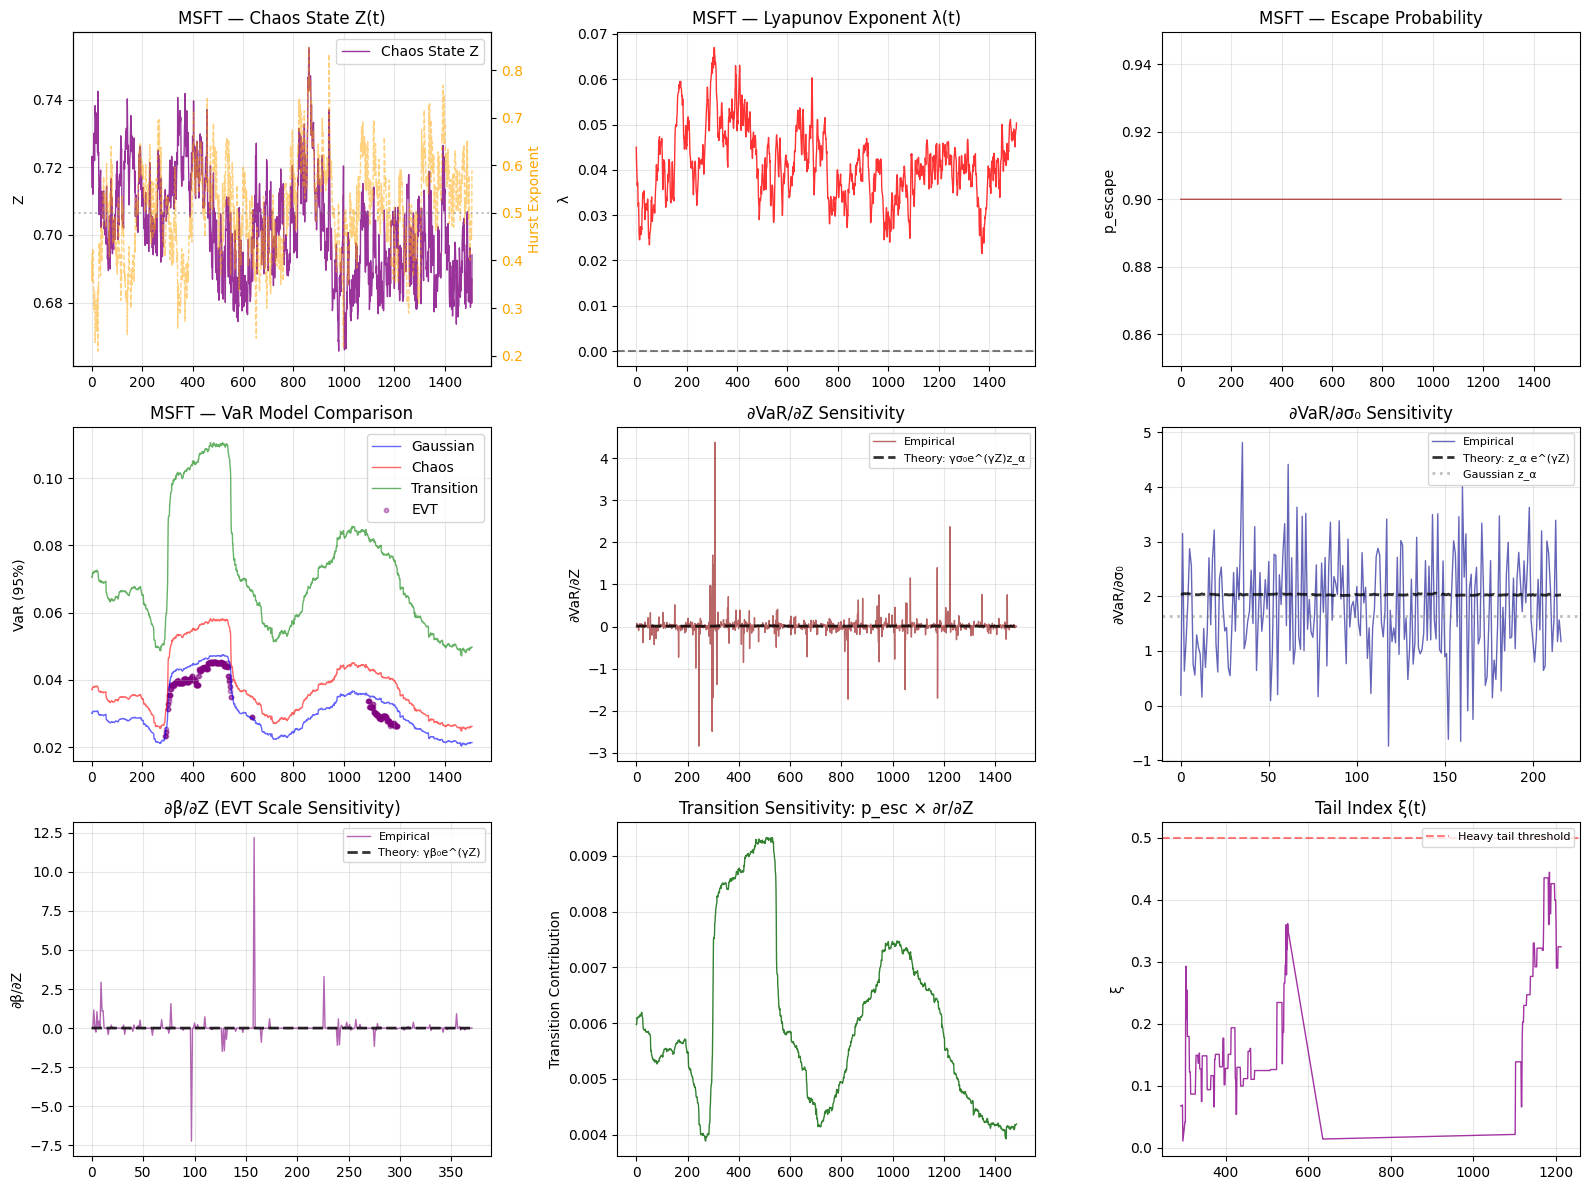


MSFT Enhanced Summary:
  Mean Chaos State Z: 0.7025
  Mean Hurst H: 0.5069 (persistent)
  Mean Lyapunov λ: 0.041078 (chaotic)
  Mean Escape Prob: 0.9000
  VaR Inflation (Chaos/Gauss): 22.73%
  VaR Inflation (Transition/Gauss): 133.18%
  Mean ∂VaR/∂Z (empirical): 0.011031
  Mean ∂VaR/∂Z (theoretical): 0.011051
  Mean ∂VaR/∂σ₀ (empirical): 1.7864
  Mean ∂VaR/∂σ₀ (theoretical): 2.0306
  Mean ∂β/∂Z (empirical): 0.037991
  Mean ∂β/∂Z (theoretical): 0.006216
  Mean Transition Sensitivity: 0.006046
  Gaussian baseline z_α: 1.6449

Processing TSLA...


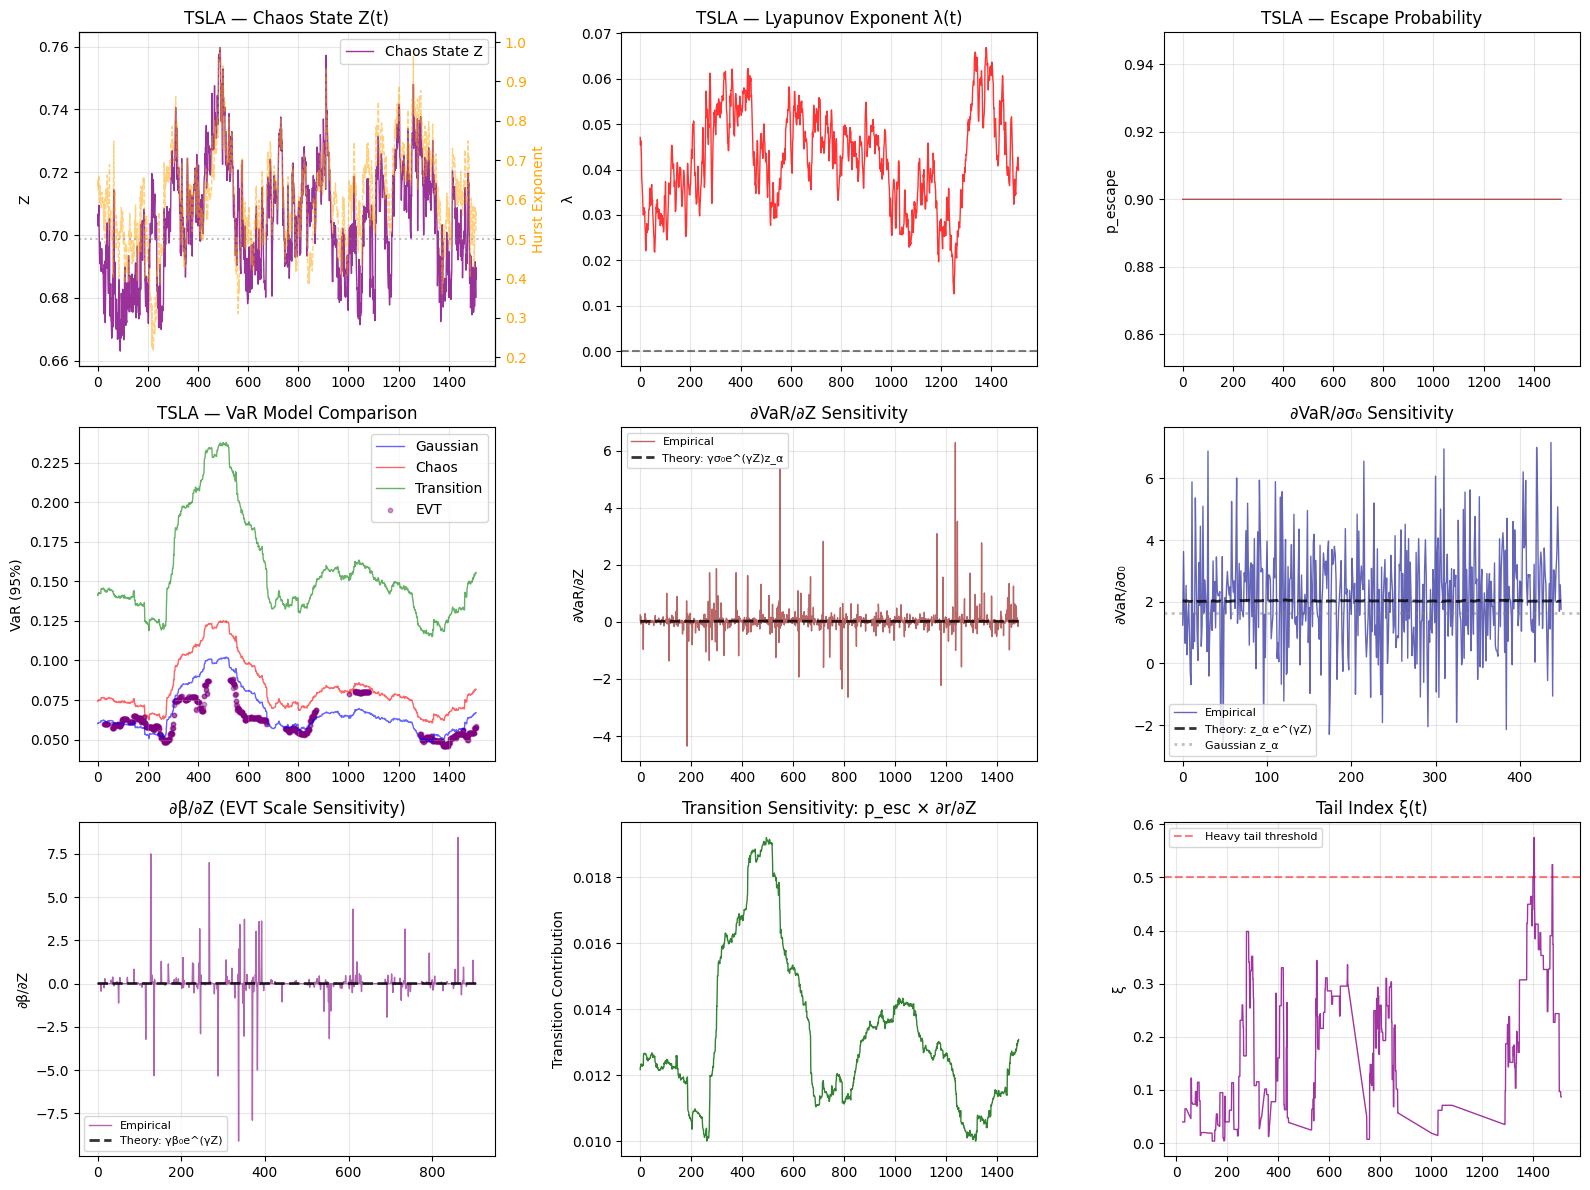


TSLA Enhanced Summary:
  Mean Chaos State Z: 0.7040
  Mean Hurst H: 0.6060 (persistent)
  Mean Lyapunov λ: 0.042176 (chaotic)
  Mean Escape Prob: 0.9000
  VaR Inflation (Chaos/Gauss): 23.00%
  VaR Inflation (Transition/Gauss): 133.70%
  Mean ∂VaR/∂Z (empirical): 0.040247
  Mean ∂VaR/∂Z (theoretical): 0.024212
  Mean ∂VaR/∂σ₀ (empirical): 2.1401
  Mean ∂VaR/∂σ₀ (theoretical): 2.0316
  Mean ∂β/∂Z (empirical): 0.018070
  Mean ∂β/∂Z (theoretical): 0.008555
  Mean Transition Sensitivity: 0.013247
  Gaussian baseline z_α: 1.6449

Processing BTC-USD...


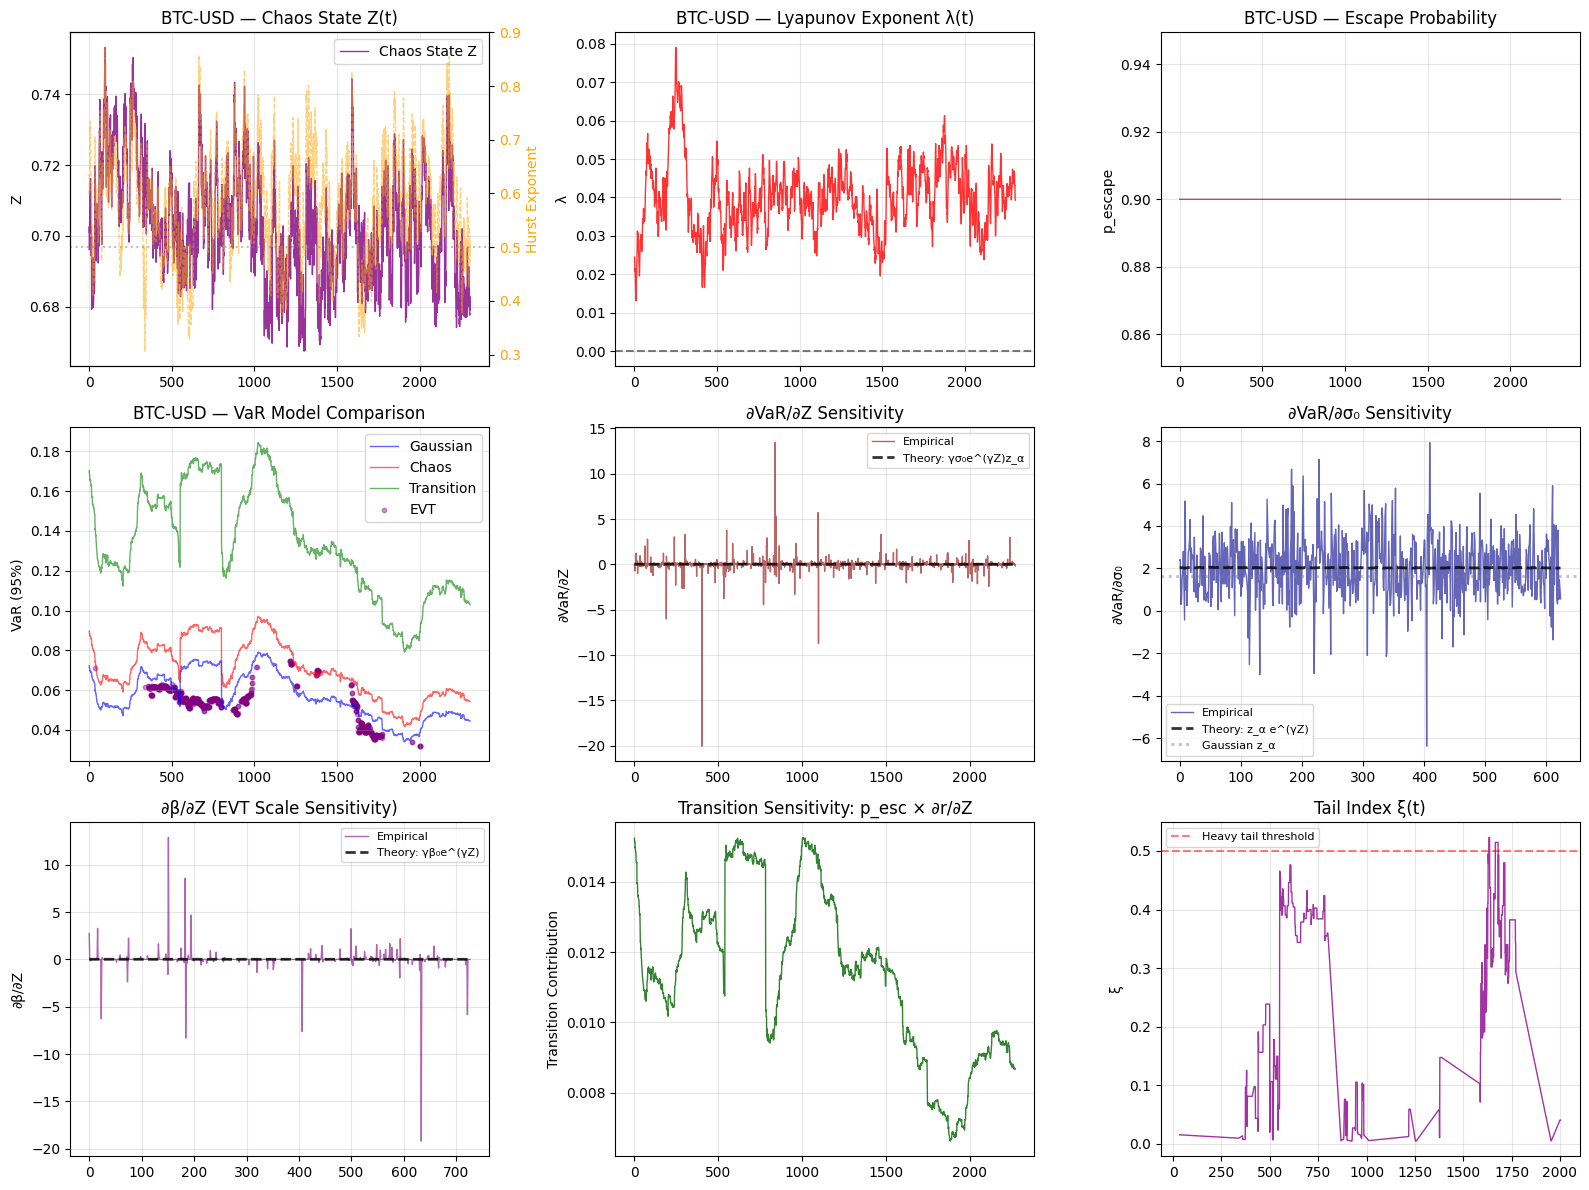


BTC-USD Enhanced Summary:
  Mean Chaos State Z: 0.7028
  Mean Hurst H: 0.5815 (persistent)
  Mean Lyapunov λ: 0.040022 (chaotic)
  Mean Escape Prob: 0.9000
  VaR Inflation (Chaos/Gauss): 23.10%
  VaR Inflation (Transition/Gauss): 133.88%
  Mean ∂VaR/∂Z (empirical): 0.010917
  Mean ∂VaR/∂Z (theoretical): 0.020809
  Mean ∂VaR/∂σ₀ (empirical): 2.0652
  Mean ∂VaR/∂σ₀ (theoretical): 2.0314
  Mean ∂β/∂Z (empirical): -0.001498
  Mean ∂β/∂Z (theoretical): 0.008185
  Mean Transition Sensitivity: 0.011385
  Gaussian baseline z_α: 1.6449

Enhanced Chaos Differentiation Analysis Complete!


In [18]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, genpareto
from scipy.spatial.distance import pdist, squareform
from sklearn.neighbors import NearestNeighbors

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL", "MSFT", "TSLA", "BTC-USD"]
start = "2018-01-01"
end = "2025-01-01"
window = 250
alpha = 0.95
z = norm.ppf(alpha)
gamma = 0.3  # Chaos sensitivity parameter

min_dZ = 1e-4  # Filter tiny chaos changes
min_exceedances = 15  # EVT fitting

# -----------------------------
# Hurst Exponent
# -----------------------------
def compute_hurst(returns):
    """Compute Hurst exponent via R/S analysis"""
    N = len(returns)
    if N < 20:
        return 0.5
    max_k = N // 2
    rs = []
    lags = range(10, max_k, max(1, max_k//20))
    for lag in lags:
        y = returns[:lag]
        mean_y = np.mean(y)
        Z = np.cumsum(y - mean_y)
        R = np.max(Z) - np.min(Z)
        S = np.std(y)
        if S > 0:
            rs.append(R / S)
    if len(rs) < 2:
        return 0.5
    H = np.polyfit(np.log(list(lags[:len(rs)])), np.log(rs), 1)[0]
    return H

# -----------------------------
# Lyapunov Exponent
# -----------------------------
def compute_lyapunov(returns, m=2, tau=1, max_t=10):
    """Compute largest Lyapunov exponent"""
    returns = np.asarray(returns).squeeze()
    N = len(returns)
    if N < m + max_t + 10:
        return 0.0
    
    # Sliding window embedding
    X = np.array([returns[i:i+m] for i in range(0, N-m+1, tau)])
    if len(X) <= m + max_t:
        return 0.0
    
    nbrs = NearestNeighbors(n_neighbors=2, algorithm='ball_tree').fit(X)
    distances, indices = nbrs.kneighbors(X)
    nearest_idx = indices[:, 1]
    dist0 = distances[:, 1]
    
    L = []
    for i in range(1, max_t):
        di = []
        for j in range(min(len(X)-i, len(nearest_idx))):
            ni = nearest_idx[j]
            if ni + i >= len(X):
                continue
            d = np.linalg.norm(X[j+i] - X[ni+i])
            if dist0[j] > 1e-10 and d > 1e-10:
                di.append(np.log(d / dist0[j]))
        if len(di) > 0:
            L.append(np.mean(di))
    
    if len(L) < 2:
        return 0.0
    lam = np.polyfit(np.arange(len(L)), L, 1)[0]
    return lam

# -----------------------------
# Chaos State Computation (Enhanced)
# -----------------------------
def compute_chaos_state(returns, m=3, tau=1, threshold_pct=10):
    """Enhanced chaos state with Hurst and Lyapunov"""
    # Ensure returns is 1D array - force it aggressively
    if hasattr(returns, 'values'):
        returns = returns.values
    returns = np.asarray(returns).squeeze()
    
    # Time-delay embedding
    N = len(returns)
    M = N - (m - 1) * tau
    if M <= 0:
        return 0.1, 0.5, 0.0, {}  # Default values
    
    embedded = np.zeros((M, m))
    for i in range(m):
        start_idx = i * tau
        end_idx = start_idx + M
        slice_data = returns[start_idx:end_idx]
        embedded[:, i] = np.asarray(slice_data).squeeze()
    
    # Recurrence plot
    dist_matrix = squareform(pdist(embedded, metric='euclidean'))
    threshold = np.percentile(dist_matrix, threshold_pct)
    R = (dist_matrix <= threshold).astype(int)
    
    # RQA metrics
    RR = np.sum(R) / (M * M)
    
    # Determinism
    diag_lines = []
    for k in range(1, M):
        diag = np.diag(R, k)
        in_line = False
        length = 0
        for val in diag:
            if val == 1:
                length += 1
                in_line = True
            else:
                if length >= 2:
                    diag_lines.append(length)
                length = 0
        if length >= 2:
            diag_lines.append(length)
    
    DET = sum(diag_lines) / np.sum(R) if len(diag_lines) > 0 and np.sum(R) > 0 else 0
    
    # Laminarity (vertical lines)
    vert_lines = []
    for j in range(M):
        col = R[:, j]
        in_line = False
        length = 0
        for val in col:
            if val == 1:
                length += 1
            else:
                if length >= 2:
                    vert_lines.append(length)
                length = 0
        if length >= 2:
            vert_lines.append(length)
    
    LAM = sum(vert_lines) / np.sum(R) if len(vert_lines) > 0 and np.sum(R) > 0 else 0
    
    # Entropy
    if len(diag_lines) > 0:
        hist, _ = np.histogram(diag_lines, bins=range(2, max(diag_lines)+2))
        probs = hist / sum(hist)
        probs = probs[probs > 0]
        ENTR = -np.sum(probs * np.log(probs))
    else:
        ENTR = 0
    
    # Escape probability
    p_escape = 1 - RR if RR > 0 else 0
    
    # Compute Hurst and Lyapunov
    H = compute_hurst(returns)
    lam = compute_lyapunov(returns)
    
    # Enhanced chaos state
    Z = (
        2.0 * max(lam, 0) +  # Positive Lyapunov = chaos
        (1 - DET) +          # Low determinism = chaos
        ENTR +               # High entropy = chaos
        RR +                 # Recurrence contribution
        abs(H - 0.5) * 2     # Distance from random walk
    )
    Z_norm = Z / (1 + abs(Z))
    
    metrics = {
        'RR': RR, 'DET': DET, 'LAM': LAM, 'ENTR': ENTR,
        'p_escape': p_escape, 'H': H, 'lam': lam
    }
    
    return Z_norm, H, lam, metrics

# -----------------------------
# EVT Computation
# -----------------------------
def compute_evt_var(losses, Z, confidence_level=0.95):
    """Compute chaos-conditioned EVT VaR"""
    # Find threshold
    for q in np.linspace(0.90, 0.95, 6):
        u = np.quantile(losses, q)
        exceedances = losses[losses > u] - u
        if len(exceedances) >= min_exceedances:
            break
    else:
        return np.nan, np.nan, np.nan
    
    Nu, N = len(exceedances), len(losses)
    try:
        xi, _, beta = genpareto.fit(exceedances, floc=0)
    except:
        return np.nan, np.nan, np.nan
    
    # Chaos-modulated scale
    beta_chaos = beta * np.exp(gamma * Z)
    
    p_tail = 1 - confidence_level
    if 0 < xi < 1:
        VaR_evt = u + (beta_chaos / xi) * ((p_tail * N / Nu) ** (-xi) - 1)
    else:
        VaR_evt = np.nan
    
    return VaR_evt, beta, xi

# -----------------------------
# Loop over assets
# -----------------------------
for ticker in tickers:
    print(f"\nProcessing {ticker}...")
    df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    prices = df["Close"].dropna()
    returns = np.log(prices / prices.shift(1)).dropna().values
    losses = -returns
    
    VaR_gauss = []
    VaR_chaos = []
    VaR_evt_list = []
    VaR_transition = []
    sigma_base = []
    Z_series = []
    H_series = []
    lam_series = []
    p_escape_series = []
    beta_series = []
    xi_series = []
    
    for i in range(window, len(returns)):
        r_win = returns[i - window:i]
        r_win = np.asarray(r_win).ravel()
        l_win = losses[i - window:i]
        
        mu_t = r_win.mean()
        sigma_t = r_win.std(ddof=1)
        
        # Enhanced chaos state
        Z_t, H_t, lam_t, metrics = compute_chaos_state(r_win)
        
        # Gaussian VaR
        VaR_g = mu_t + z * sigma_t
        
        # Chaos-conditioned VaR: σ(Z) = σ₀ * exp(γZ)
        sigma_chaos = sigma_t * np.exp(gamma * Z_t)
        VaR_c = mu_t + z * sigma_chaos
        
        # EVT VaR
        VaR_e, beta_t, xi_t = compute_evt_var(l_win, Z_t, alpha)
        
        # Transition-aware VaR
        p_esc = metrics['p_escape']
        VaR_trans = VaR_c * (1 + p_esc)
        
        VaR_gauss.append(VaR_g)
        VaR_chaos.append(VaR_c)
        VaR_evt_list.append(VaR_e)
        VaR_transition.append(VaR_trans)
        sigma_base.append(sigma_t)
        Z_series.append(Z_t)
        H_series.append(H_t)
        lam_series.append(lam_t)
        p_escape_series.append(p_esc)
        beta_series.append(beta_t if not np.isnan(beta_t) else 0)
        xi_series.append(xi_t if not np.isnan(xi_t) else 0)
    
    VaR_gauss = np.array(VaR_gauss)
    VaR_chaos = np.array(VaR_chaos)
    VaR_evt_list = np.array(VaR_evt_list)
    VaR_transition = np.array(VaR_transition)
    sigma_base = np.array(sigma_base)
    Z_series = np.array(Z_series)
    H_series = np.array(H_series)
    lam_series = np.array(lam_series)
    p_escape_series = np.array(p_escape_series)
    beta_series = np.array(beta_series)
    xi_series = np.array(xi_series)
    
    # -----------------------------
    # Empirical Derivatives
    # -----------------------------
    
    # 1. dVaR_chaos/dZ
    dVaR_chaos = np.diff(VaR_chaos)
    dZ = np.diff(Z_series)
    mask_Z = np.abs(dZ) > min_dZ
    sensitivity_Z = dVaR_chaos[mask_Z] / dZ[mask_Z]
    theoretical_dVaR_dZ = gamma * sigma_base[:-1][mask_Z] * np.exp(gamma * Z_series[:-1][mask_Z]) * z
    
    # 2. dVaR_chaos/dσ₀
    dVaR = np.diff(VaR_chaos)
    dSigma = np.diff(sigma_base)
    mask_sigma = np.abs(dSigma) > min_dZ
    sensitivity_sigma = dVaR[mask_sigma] / dSigma[mask_sigma]
    theoretical_dVaR_dsigma = z * np.exp(gamma * Z_series[:-1][mask_sigma])
    
    # 3. dβ/dZ (EVT scale parameter)
    valid_beta = (beta_series > 0) & (xi_series > 0)
    if np.sum(valid_beta) > 10:
        beta_valid = beta_series[valid_beta]
        Z_valid = Z_series[valid_beta]
        
        dBeta = np.diff(beta_valid)
        dZ_beta = np.diff(Z_valid)
        mask_beta = (np.abs(dZ_beta) > min_dZ) & (beta_valid[:-1] > 0)
        
        if np.sum(mask_beta) > 0:
            sensitivity_beta = dBeta[mask_beta] / dZ_beta[mask_beta]
            theoretical_dBeta_dZ = gamma * beta_valid[:-1][mask_beta] * \
                                   np.exp(gamma * Z_valid[:-1][mask_beta])
        else:
            sensitivity_beta = np.array([])
            theoretical_dBeta_dZ = np.array([])
    else:
        sensitivity_beta = np.array([])
        theoretical_dBeta_dZ = np.array([])
    
    # 4. Transition sensitivity: p_escape × ∂r/∂Z
    transition_sensitivity = p_escape_series[:-1][mask_Z] * \
                            (gamma * sigma_base[:-1][mask_Z] * np.exp(gamma * Z_series[:-1][mask_Z]))
    
    # -----------------------------
    # Plotting
    # -----------------------------
    fig = plt.figure(figsize=(16, 12))
    
    # Plot 1: Chaos State with Hurst & Lyapunov
    ax1 = plt.subplot(3, 3, 1)
    ax1.plot(Z_series, linewidth=1, alpha=0.8, color='purple', label='Chaos State Z')
    ax1.set_title(f"{ticker} — Chaos State Z(t)")
    ax1.set_ylabel("Z")
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    ax1_twin = ax1.twinx()
    ax1_twin.plot(H_series, linewidth=1, alpha=0.5, color='orange', linestyle='--', label='Hurst')
    ax1_twin.axhline(0.5, color='gray', linestyle=':', alpha=0.5)
    ax1_twin.set_ylabel("Hurst Exponent", color='orange')
    ax1_twin.tick_params(axis='y', labelcolor='orange')
    
    # Plot 2: Lyapunov Exponent
    ax2 = plt.subplot(3, 3, 2)
    ax2.plot(lam_series, linewidth=1, alpha=0.8, color='red')
    ax2.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax2.set_title(f"{ticker} — Lyapunov Exponent λ(t)")
    ax2.set_ylabel("λ")
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: Escape Probability
    ax3 = plt.subplot(3, 3, 3)
    ax3.plot(p_escape_series, linewidth=1, alpha=0.8, color='brown')
    ax3.set_title(f"{ticker} — Escape Probability")
    ax3.set_ylabel("p_escape")
    ax3.grid(True, alpha=0.3)
    
    # Plot 4: VaR Comparison (All Models)
    ax4 = plt.subplot(3, 3, 4)
    ax4.plot(VaR_gauss, linewidth=1, alpha=0.6, label='Gaussian', color='blue')
    ax4.plot(VaR_chaos, linewidth=1, alpha=0.6, label='Chaos', color='red')
    ax4.plot(VaR_transition, linewidth=1, alpha=0.6, label='Transition', color='green')
    valid_evt = ~np.isnan(VaR_evt_list)
    if np.sum(valid_evt) > 0:
        ax4.scatter(np.where(valid_evt)[0], VaR_evt_list[valid_evt], 
                   s=10, alpha=0.4, label='EVT', color='purple')
    ax4.set_title(f"{ticker} — VaR Model Comparison")
    ax4.set_ylabel("VaR (95%)")
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    # Plot 5: ∂VaR/∂Z Sensitivity
    ax5 = plt.subplot(3, 3, 5)
    t_Z = np.arange(len(sensitivity_Z))
    ax5.plot(t_Z, sensitivity_Z, linewidth=1, alpha=0.6, label='Empirical', color='darkred')
    ax5.plot(t_Z, theoretical_dVaR_dZ, linewidth=2, linestyle='--', alpha=0.8, 
             label='Theory: γσ₀e^(γZ)z_α', color='black')
    ax5.set_title(f"∂VaR/∂Z Sensitivity")
    ax5.set_ylabel("∂VaR/∂Z")
    ax5.legend(fontsize=8)
    ax5.grid(True, alpha=0.3)
    
    # Plot 6: ∂VaR/∂σ₀ Sensitivity
    ax6 = plt.subplot(3, 3, 6)
    t_sigma = np.arange(len(sensitivity_sigma))
    ax6.plot(t_sigma, sensitivity_sigma, linewidth=1, alpha=0.6, label='Empirical', color='darkblue')
    ax6.plot(t_sigma, theoretical_dVaR_dsigma, linewidth=2, linestyle='--', alpha=0.8,
             label='Theory: z_α e^(γZ)', color='black')
    ax6.axhline(z, linestyle=':', linewidth=2, alpha=0.5, label='Gaussian z_α', color='gray')
    ax6.set_title(f"∂VaR/∂σ₀ Sensitivity")
    ax6.set_ylabel("∂VaR/∂σ₀")
    ax6.legend(fontsize=8)
    ax6.grid(True, alpha=0.3)
    
    # Plot 7: ∂β/∂Z (EVT Scale Derivative)
    ax7 = plt.subplot(3, 3, 7)
    if len(sensitivity_beta) > 0:
        t_beta = np.arange(len(sensitivity_beta))
        ax7.plot(t_beta, sensitivity_beta, linewidth=1, alpha=0.6, label='Empirical', color='purple')
        ax7.plot(t_beta, theoretical_dBeta_dZ, linewidth=2, linestyle='--', alpha=0.8,
                 label='Theory: γβ₀e^(γZ)', color='black')
        ax7.set_title(f"∂β/∂Z (EVT Scale Sensitivity)")
        ax7.set_ylabel("∂β/∂Z")
        ax7.legend(fontsize=8)
    else:
        ax7.text(0.5, 0.5, 'Insufficient EVT data', ha='center', va='center', transform=ax7.transAxes)
        ax7.set_title(f"∂β/∂Z (EVT Scale Sensitivity)")
    ax7.grid(True, alpha=0.3)
    
    # Plot 8: Transition Sensitivity
    ax8 = plt.subplot(3, 3, 8)
    t_trans = np.arange(len(transition_sensitivity))
    ax8.plot(t_trans, transition_sensitivity, linewidth=1, alpha=0.8, color='darkgreen')
    ax8.set_title(f"Transition Sensitivity: p_esc × ∂r/∂Z")
    ax8.set_ylabel("Transition Contribution")
    ax8.grid(True, alpha=0.3)
    
    # Plot 9: Tail Index Evolution
    ax9 = plt.subplot(3, 3, 9)
    valid_xi = xi_series > 0
    if np.sum(valid_xi) > 0:
        ax9.plot(np.where(valid_xi)[0], xi_series[valid_xi], linewidth=1, alpha=0.8, color='darkmagenta')
        ax9.axhline(0.5, color='red', linestyle='--', alpha=0.5, label='Heavy tail threshold')
        ax9.set_title(f"Tail Index ξ(t)")
        ax9.set_ylabel("ξ")
        ax9.legend(fontsize=8)
    else:
        ax9.text(0.5, 0.5, 'No valid tail estimates', ha='center', va='center', transform=ax9.transAxes)
        ax9.set_title(f"Tail Index ξ(t)")
    ax9.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'chaos_sensitivity_enhanced_{ticker}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # -----------------------------
    # Summary Statistics
    # -----------------------------
    print(f"\n{ticker} Enhanced Summary:")
    print(f"  Mean Chaos State Z: {Z_series.mean():.4f}")
    print(f"  Mean Hurst H: {H_series.mean():.4f} ({'persistent' if H_series.mean() > 0.5 else 'mean-reverting'})")
    print(f"  Mean Lyapunov λ: {lam_series.mean():.6f} ({'chaotic' if lam_series.mean() > 0 else 'stable'})")
    print(f"  Mean Escape Prob: {p_escape_series.mean():.4f}")
    print(f"  VaR Inflation (Chaos/Gauss): {((VaR_chaos.mean() / VaR_gauss.mean()) - 1)*100:.2f}%")
    print(f"  VaR Inflation (Transition/Gauss): {((VaR_transition.mean() / VaR_gauss.mean()) - 1)*100:.2f}%")
    print(f"  Mean ∂VaR/∂Z (empirical): {np.mean(sensitivity_Z):.6f}")
    print(f"  Mean ∂VaR/∂Z (theoretical): {np.mean(theoretical_dVaR_dZ):.6f}")
    print(f"  Mean ∂VaR/∂σ₀ (empirical): {np.mean(sensitivity_sigma):.4f}")
    print(f"  Mean ∂VaR/∂σ₀ (theoretical): {np.mean(theoretical_dVaR_dsigma):.4f}")
    if len(sensitivity_beta) > 0:
        print(f"  Mean ∂β/∂Z (empirical): {np.mean(sensitivity_beta):.6f}")
        print(f"  Mean ∂β/∂Z (theoretical): {np.mean(theoretical_dBeta_dZ):.6f}")
    print(f"  Mean Transition Sensitivity: {np.mean(transition_sensitivity):.6f}")
    print(f"  Gaussian baseline z_α: {z:.4f}")

print("\n" + "="*80)
print("Enhanced Chaos Differentiation Analysis Complete!")
print("="*80)